In [150]:
import nnsight
from nnsight import TransformersModel
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
model = TransformersModel("meta-llama/Llama-3.1-8B")

In [36]:
prompt = "Q: What month is three months after November?\nA:"

In [40]:
[model.tokenizer.decode(x) for x in model.tokenizer.encode(prompt)]

['<|begin_of_text|>',
 'Q',
 ':',
 ' What',
 ' month',
 ' is',
 ' three',
 ' months',
 ' after',
 ' November',
 '?\n',
 'A',
 ':']

In [129]:
with model.trace(prompt, remote=True):
    h = nnsight.save([model.model.layers[i].output for i in range(len(model.model.layers))])
    preds = model.output.logits.save()

In [113]:
probs, indices = torch.topk(preds[0,-1,:].softmax(dim=0), k=12)
for i in range(len(probs)):
    print(f"{repr(model.tokenizer.decode(indices[i]))}: {probs[i]}")

' February': 0.7265625
' The': 0.031982421875
' It': 0.0281982421875
' January': 0.01177978515625
' Two': 0.01104736328125
' March': 0.0091552734375
' That': 0.0091552734375
' If': 0.00860595703125
' December': 0.008056640625
' In': 0.008056640625
'\xa0': 0.007598876953125
' ': 0.0067138671875


In [58]:
norms = [torch.linalg.norm(l, dim=-1).to(torch.float16) for l in h]

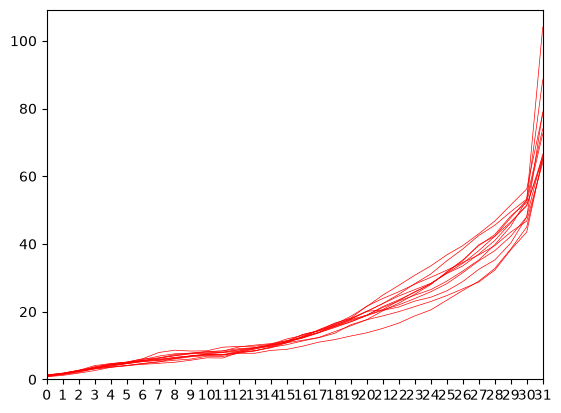

In [69]:
for t in range(1, h[0].shape[1]):
    plt.plot(range(len(h)), [l[-1, t] for l in norms], color='red', linewidth=0.5)
plt.xticks(range(len(h)))
plt.xlim(0, 31)
plt.ylim(bottom=0)
plt.show()

In [197]:
months = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
increments = ["one", "two", "three", "four", "five", "six", "seven", "eight", "nine", "ten", "eleven", "twelve"]

In [198]:
resids = {}
logits = {}
for m in months:
    print(f"Running '{m}' prompts:")
    if "month_resids" in locals():
        del month_resids 
    if "month_logits" in locals():
        del month_logits
    with model.trace(remote=True) as tracer:
        month_resids = nnsight.save({})
        month_logits = nnsight.save({})
        for k in increments:
            with tracer.invoke(f"Q: What is {k} month{"" if k == "one" else "s"} after {m}?\nA:"):
                month_resids[k] = model.model.layers[27].output[0, -1]
                month_logits[k] = model.output.logits[0, -1]
    
    for k in increments:
        resids[(m, k)] = month_resids[k]
        logits[(m, k)] = month_logits[k]

Running 'January' prompts:


Running 'February' prompts:


Running 'March' prompts:


Running 'April' prompts:


Running 'May' prompts:


Running 'June' prompts:


... (2 outputs left out)

Running 'September' prompts:


Running 'October' prompts:


Running 'November' prompts:


Running 'December' prompts:


In [200]:
combined = torch.stack(list(resids.values()), dim=0).float()

In [201]:
from sklearn.decomposition import PCA

In [202]:
pca = PCA(n_components=3, random_state=42)
Z = pca.fit_transform(combined)

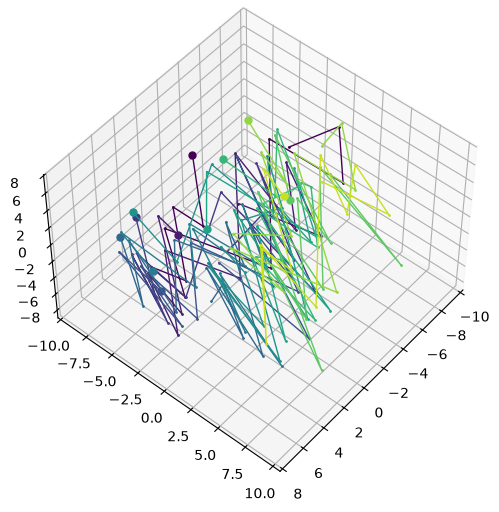

In [203]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')
for i, m in enumerate(months):
    ids = [i * len(increments) + j for j in range(len(increments))]
    cmap = plt.colormaps["viridis"]
    ax.plot(Z[[ids[0]], 0], Z[[ids[0]], 1], Z[[ids[0]], 2], color=cmap(i / len(months)), marker="o", ms=5)
    ax.plot(Z[ids, 0], Z[ids, 1], Z[ids, 2], color=cmap(i / len(months)), marker="o", ms=1, linewidth=1)
ax.view_init(elev=50, azim=40, roll=0)
plt.show()

In [194]:
import plotly.graph_objects as go
import plotly.express as px

In [206]:
def fancy_plot(Z):
    fig = go.Figure()
    colors = px.colors.qualitative.Alphabet

    for i, m in enumerate(months):
        ids = [i * len(increments) + j for j in range(len(increments))]
        coords = Z[ids, :3]

        fig.add_trace(go.Scatter3d(
            x=coords[:, 0],
            y=coords[:, 1],
            z=coords[:, 2],
            mode="lines+markers",
            name=m,
            legendgroup=m,
            line=dict(color=colors[i], width=4),
            marker=dict(
                color=colors[i],
                size=5,
            ),
            text=[increments[j] for j in range(len(ids))],
            hovertemplate=(
                f"Starting month: {m}<br>"
                "Increment: %{text}<br>"
                "PC1: %{x:.2f}<br>"
                "PC2: %{y:.2f}<br>"
                "PC3: %{z:.2f}<extra></extra>"
            ),
        ))

    fig.update_layout(
        title="Month Arithmetic — Layer 27 Residual Geometry",
        scene=dict(
            xaxis_title=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})",
            yaxis_title=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})",
            zaxis_title=f"PC3 ({pca.explained_variance_ratio_[2]:.1%})",
            aspectmode="data",
        ),
        width=1000,
        height=800,
    )

    fig.show(renderer="browser")

In [207]:
fancy_plot(Z)

/usr/bin/xdg-open: 882: x-www-browser: not found
/usr/bin/xdg-open: 882: firefox: not found
/usr/bin/xdg-open: 882: iceweasel: not found
/usr/bin/xdg-open: 882: seamonkey: not found
/usr/bin/xdg-open: 882: mozilla: not found
/usr/bin/xdg-open: 882: epiphany: not found
/usr/bin/xdg-open: 882: konqueror: not found
/usr/bin/xdg-open: 882: chromium: not found
/usr/bin/xdg-open: 882: chromium-browser: not found
/usr/bin/xdg-open: 882: google-chrome: not found
/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening 'http://127.0.0.1:45066'


In [208]:
U, S, Vt = np.linalg.svd(combined, full_matrices=False)
Z_svd = combined @ Vt[:3].T

In [209]:
fancy_plot(Z_svd)

/usr/bin/xdg-open: 882: x-www-browser: not found
/usr/bin/xdg-open: 882: firefox: not found
/usr/bin/xdg-open: 882: iceweasel: not found
/usr/bin/xdg-open: 882: seamonkey: not found
/usr/bin/xdg-open: 882: mozilla: not found
/usr/bin/xdg-open: 882: epiphany: not found
/usr/bin/xdg-open: 882: konqueror: not found
/usr/bin/xdg-open: 882: chromium: not found
/usr/bin/xdg-open: 882: chromium-browser: not found
/usr/bin/xdg-open: 882: google-chrome: not found
/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening 'http://127.0.0.1:44354'


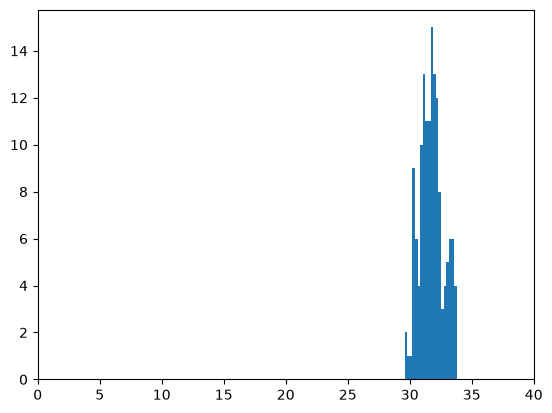

In [218]:
plt.hist(torch.linalg.norm(combined, dim=1), bins=20)
plt.xlim(0, 40)
plt.show()